# User-plane performance plots

Makes the three-panel figure (throughput, RTT, jitter) for each simulation group.

**Before running:** put this notebook next to your `5g_open_source_benchmarking` folder,
or change `RESULTS_DIR` in the first code cell to wherever the `results` folder is.

Run the cells from top to bottom (Shift + Enter). The figures appear in the notebook and are also saved as PNG files.

In [1]:
import re
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ---- Settings you may need to change ----
RESULTS_DIR = Path("5g_open_source_benchmarking/results")   # folder that contains 5g_benchmark_results and 5g_split_ue
OUTPUT_DIR = Path("figures")                               # where the PNG files are saved
OUTPUT_DIR.mkdir(exist_ok=True)

%config InlineBackend.figure_format = "retina"

# ---- Colours ----
# Colour = core network, white hatching = split architecture.
# To change colours, set PALETTE to one of the names below (see the "Colour choices" section).
PALETTES = {
    "blue_coral":       {"open5gs": "#1F6FB2", "free5gc": "#EE6B5E"},  # current choice
    "navy_coral":       {"open5gs": "#1F3A5F", "free5gc": "#EE6B5E"},  # better for black-and-white printing
    "blue_vermillion":  {"open5gs": "#0072B2", "free5gc": "#D55E00"},  # colour-blind safe
    "teal_coral":       {"open5gs": "#00798C", "free5gc": "#D1495B"},
    "navy_gold":        {"open5gs": "#1F3A5F", "free5gc": "#E3A72F"},  # most formal, prints well
    "purple_green":     {"open5gs": "#5E4FA2", "free5gc": "#3AA17E"},
}
PALETTE = "blue_coral"
CORE_COLOURS = PALETTES[PALETTE]

CORE_NAMES = {"open5gs": "Open5GS", "free5gc": "free5GC"}
OUTLINE = "#222222"   # colour of bar outlines, error bars, median lines and dots

plt.rcParams.update({
    "axes.spines.top": False,     # remove top and right borders for a cleaner look
    "axes.spines.right": False,
    "font.size": 10,
})

## Configurations

Each configuration is: (ID, core, RAN name used in the CSV, results folder, run folder name).
The IDs (S1, O1, ...) are only for your own reference and tables; the graphs use descriptive labels instead.
The RAN name must match the `ran` column in `all_results.csv`.

In [2]:
MONO = "5g_benchmark_results"
SPLIT = "5g_split_ue"

GROUPS = {
    "ocudu": {
        "title": "OCUDU + srsUE group",
        "configs": [
            ("S1", "open5gs", "srsran",      MONO,  "open5gs_srsran"),
            ("S2", "free5gc", "srsran",      MONO,  "free5gc_srsran"),
            ("S3", "open5gs", "ocudu_split", SPLIT, "open5gs_ocudu_split"),
            ("S4", "free5gc", "ocudu_split", SPLIT, "free5gc_ocudu_split"),
        ],
    },
    "oai": {
        "title": "OAI + nr-softmodem group",
        "configs": [
            ("O1", "open5gs", "oai",       MONO,  "open5gs_oai"),
            ("O2", "free5gc", "oai",       MONO,  "free5gc_oai"),
            ("O3", "open5gs", "oai_split", SPLIT, "open5gs_oai_split"),
            ("O4", "free5gc", "oai_split", SPLIT, "free5gc_oai_split"),
        ],
    },
}

## Helper functions

- `load_runs` reads the per-run results (one row per round) from both `all_results.csv` files.
- `ci95` gives the half-width of the 95% confidence interval (the length of the error bar above/below the mean).
- `load_pings` reads every individual ping time from the raw `ping_100.txt` files (100 pings x 3 rounds = 300 values).

In [3]:
def load_runs():
    """All per-run results from the monolithic and split simulation CSVs."""
    frames = [pd.read_csv(RESULTS_DIR / folder / "all_results.csv") for folder in (MONO, SPLIT)]
    return pd.concat(frames, ignore_index=True)


def ci95(values):
    """Half-width of the 95% confidence interval of the mean (t-distribution, small samples)."""
    values = np.asarray(values, dtype=float)
    n = len(values)
    if n < 2:
        return 0.0
    t = stats.t.ppf(0.975, df=n - 1)          # 4.303 when n = 3
    return t * values.std(ddof=1) / np.sqrt(n)


def load_pings(results_folder, run_folder):
    """Every individual ping time (ms) for one configuration, across all rounds."""
    times = []
    pattern = RESULTS_DIR / results_folder / "round*" / run_folder / "raw" / "ping_100.txt"
    for path in sorted(glob.glob(str(pattern))):
        text = Path(path).read_text(errors="ignore")
        times += [float(t) for t in re.findall(r"time=([\d.]+)", text)]
    return np.array(times)


def config_label(core, ran, sep="\n"):
    """Descriptive label, e.g. 'Open5GS\nSplit (CU/DU)'. Use sep=' – ' for one-line legend labels."""
    arch = "Split (CU/DU)" if "split" in ran else "Monolithic"
    return f"{CORE_NAMES[core]}{sep}{arch}"


def styled_bar(ax, x, height, width, core, ran, label=None):
    """Bar in the core's colour; split configurations get white hatching and a dark outline."""
    split = "split" in ran
    ax.bar(x, height, width, color=CORE_COLOURS[core], hatch="///" if split else None,
           edgecolor="white" if split else CORE_COLOURS[core], linewidth=0, label=label)
    ax.bar(x, height, width, fill=False, edgecolor=OUTLINE, linewidth=1)   # outline drawn on top


runs = load_runs()
runs[["core", "ran", "round", "tcp_dl_mbps", "tcp_ul_mbps", "jitter_ms"]].head(12)

,core,ran,round,tcp_dl_mbps,tcp_ul_mbps,jitter_ms
0,open5gs,oai,1,115.0,59.3,2.754
1,open5gs,srsran,1,53.6,12.4,3.299
2,open5gs,ueransim,1,900.0,899.0,0.089
3,free5gc,oai,1,122.0,81.6,2.390
4,free5gc,srsran,1,53.7,12.5,3.572
5,free5gc,ueransim,1,904.0,899.0,0.051
6,open5gs,oai,2,113.0,60.8,3.209
7,open5gs,srsran,2,53.7,12.5,3.247
8,open5gs,ueransim,2,899.0,900.0,0.067
9,free5gc,oai,2,123.0,80.8,2.209


## The plotting function

One figure, three panels:

- **(a) Throughput:** bar = mean of 3 runs, error bar = 95% confidence interval.
  (`throughput_dots=True` also draws each run as a dot; off by default.)
- **(b) RTT:** box plot of all 300 pings. Box = middle 50% of pings, line = median, whiskers = fastest and slowest ping (no outlier circles).
- **(c) Jitter:** bar = mean of 3 runs, dots = individual runs.

In [4]:
def plot_user_plane(group_key, throughput_dots=False, save=True):
    group = GROUPS[group_key]
    configs = group["configs"]
    labels = [config_label(core, ran) for _, core, ran, _, _ in configs]

    fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), gridspec_kw={"width_ratios": [1.3, 1.2, 1]})
    ax_tp, ax_rtt, ax_jit = axes

    # ---------- (a) Throughput: x-axis = direction, one bar per configuration ----------
    width = 0.2
    for k, (_, core, ran, _, _) in enumerate(configs):
        rows = runs[(runs.core == core) & (runs.ran == ran)]
        for j, metric in enumerate(["tcp_dl_mbps", "tcp_ul_mbps"]):
            values = rows[metric].dropna().values
            x = j + (k - 1.5) * width
            styled_bar(ax_tp, x, values.mean(), width, core, ran,
                       label=config_label(core, ran, " – ") if j == 0 else None)
            ax_tp.errorbar(x, values.mean(), yerr=ci95(values), color=OUTLINE, capsize=3, linewidth=1.2)
            if throughput_dots:
                ax_tp.scatter([x] * len(values), values, color=OUTLINE, s=12, zorder=4)
    ax_tp.set_xticks([0, 1])
    ax_tp.set_xticklabels(["Downlink", "Uplink"])
    ax_tp.set_ylabel("TCP throughput (Mbps)")
    ax_tp.set_title("(a) Throughput")
    ax_tp.legend(fontsize=8.5, frameon=False)

    # ---------- (b) RTT box plot from every individual ping ----------
    ping_data = [load_pings(folder, run) for _, _, _, folder, run in configs]
    # whis=(0, 100): whiskers go to the fastest (0th percentile) and slowest (100th) ping,
    # so no ping is drawn as a separate outlier circle
    box = ax_rtt.boxplot(ping_data, patch_artist=True, whis=(0, 100), showfliers=False,
                         medianprops=dict(color=OUTLINE, linewidth=1.8))
    for patch, (_, core, ran, _, _) in zip(box["boxes"], configs):
        patch.set_facecolor(CORE_COLOURS[core])
        patch.set_edgecolor(OUTLINE)
        if "split" in ran:
            patch.set_hatch("///")
            patch.set_edgecolor("white")             # white hatching ...
            (x0, y0), (x1, y1) = patch.get_path().vertices.min(0), patch.get_path().vertices.max(0)
            ax_rtt.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False,
                                           edgecolor=OUTLINE, linewidth=1, zorder=3))  # ... with a dark outline
    ax_rtt.set_xticks(range(1, len(configs) + 1))
    ax_rtt.set_xticklabels(labels, fontsize=8.5)
    ax_rtt.set_ylabel("RTT to 8.8.8.8 (ms)")
    ax_rtt.set_title(f"(b) Round-trip time ({len(ping_data[0])} pings per configuration)")

    # ---------- (c) Jitter: bar = mean, dots = individual runs ----------
    for k, (_, core, ran, _, _) in enumerate(configs):
        values = runs[(runs.core == core) & (runs.ran == ran)]["jitter_ms"].dropna().values
        styled_bar(ax_jit, k, values.mean(), 0.7, core, ran)
        ax_jit.scatter([k] * len(values), values, color=OUTLINE, s=20, zorder=4)
    ax_jit.set_xticks(range(len(configs)))
    ax_jit.set_xticklabels(labels, fontsize=8.5)
    ax_jit.set_ylabel("Jitter (ms)")
    ax_jit.set_title("(c) Jitter (UDP, 2 Mbps); dots = runs")

    for ax in axes:
        ax.grid(axis="y", alpha=0.3)
        ax.set_axisbelow(True)

    fig.suptitle(f"User-plane performance, {group['title']}", fontsize=13)
    fig.tight_layout()

    if save:
        fig.savefig(OUTPUT_DIR / f"user_plane_{group_key}.png", dpi=300)   # image, for previews
        fig.savefig(OUTPUT_DIR / f"user_plane_{group_key}.pdf")            # sharp vector version, for LaTeX
        print(f"Saved user_plane_{group_key}.png and .pdf in {OUTPUT_DIR}")
    plt.show()

    # Print the numbers behind the RTT panel, handy for writing the text
    for (_, core, ran, _, _), p in zip(configs, ping_data):
        print(f"{config_label(core, ran, ' – ')}: mean {p.mean():.1f} ms, median {np.median(p):.1f} ms, "
              f"middle 50% {np.percentile(p, 25):.1f}-{np.percentile(p, 75):.1f} ms, "
              f"range {p.min():.1f}-{p.max():.1f} ms")

## Colour choices

Colour shows the **core network** and white hatching shows the **split architecture**, so the same two colours are used in every figure.
To switch, change `PALETTE` in the first code cell and re-run all cells (Kernel → Restart & Run All).

| `PALETTE` | Open5GS | free5GC | When to choose it |
|---|---|---|---|
| `blue_coral` | medium blue | coral | Current choice. Lively and clear on screen. The two colours look similar in black-and-white printing. |
| `navy_coral` | navy | coral | Same feel as blue and coral, but the dark navy stays distinct from coral when printed in greyscale. |
| `blue_vermillion` | blue | vermillion (red-orange) | Designed to be colour-blind safe; common in scientific papers. |
| `teal_coral` | teal | deep coral | Modern and fresh; slightly less formal. |
| `navy_gold` | navy | gold | The most formal look; dark versus light, so it prints well in greyscale. |
| `purple_green` | purple | green | Distinctive, but can look less serious. |

Tips: keep the same palette for every figure in the report (including the hardware results), and check one figure in greyscale if the report will be printed.
You can also add your own pair to `PALETTES` using any hex colour codes.

## Make the figures

Saved user_plane_ocudu.png and .pdf in figures


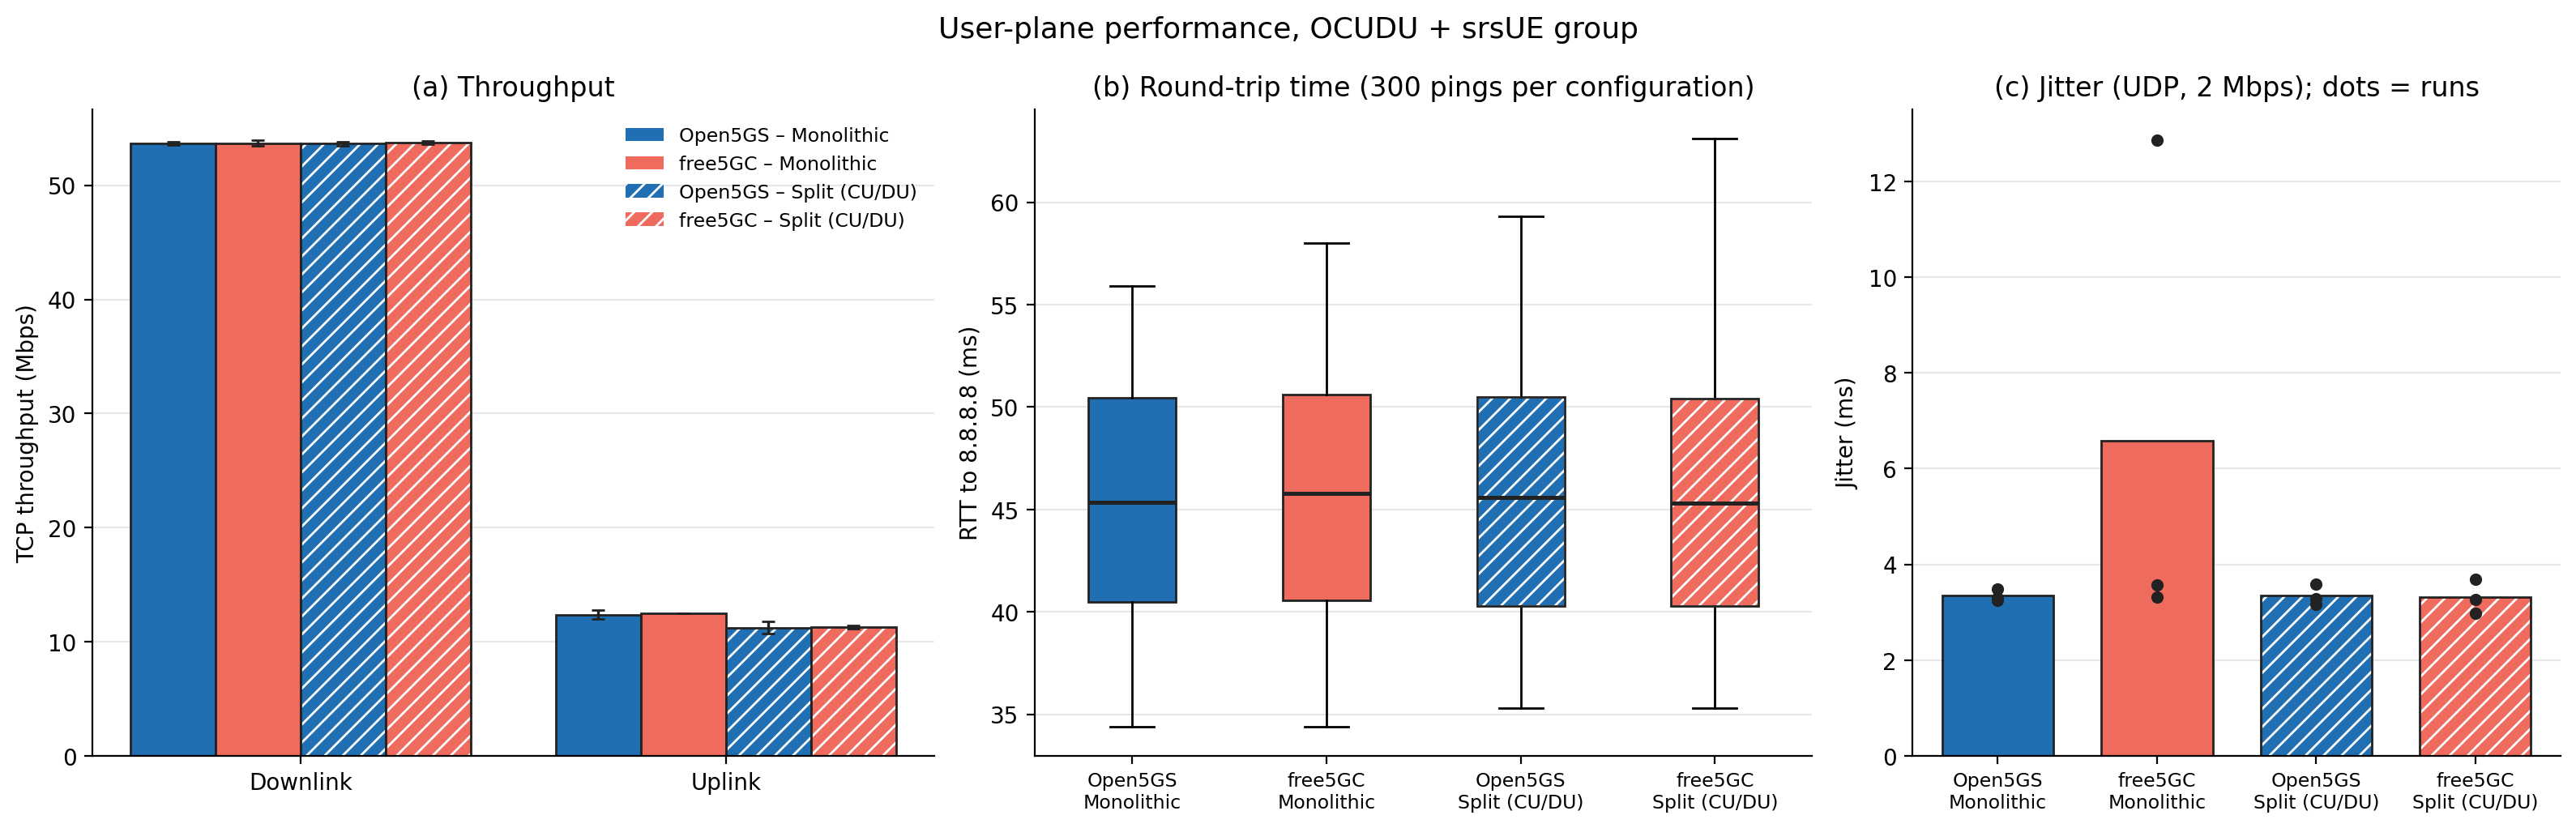

Open5GS – Monolithic: mean 45.4 ms, median 45.3 ms, middle 50% 40.5-50.5 ms, range 34.4-55.9 ms
free5GC – Monolithic: mean 45.6 ms, median 45.8 ms, middle 50% 40.5-50.6 ms, range 34.4-58.0 ms
Open5GS – Split (CU/DU): mean 45.4 ms, median 45.6 ms, middle 50% 40.3-50.5 ms, range 35.3-59.3 ms
free5GC – Split (CU/DU): mean 45.4 ms, median 45.3 ms, middle 50% 40.3-50.4 ms, range 35.3-63.1 ms


In [5]:
plot_user_plane("ocudu")

Saved user_plane_oai.png and .pdf in figures


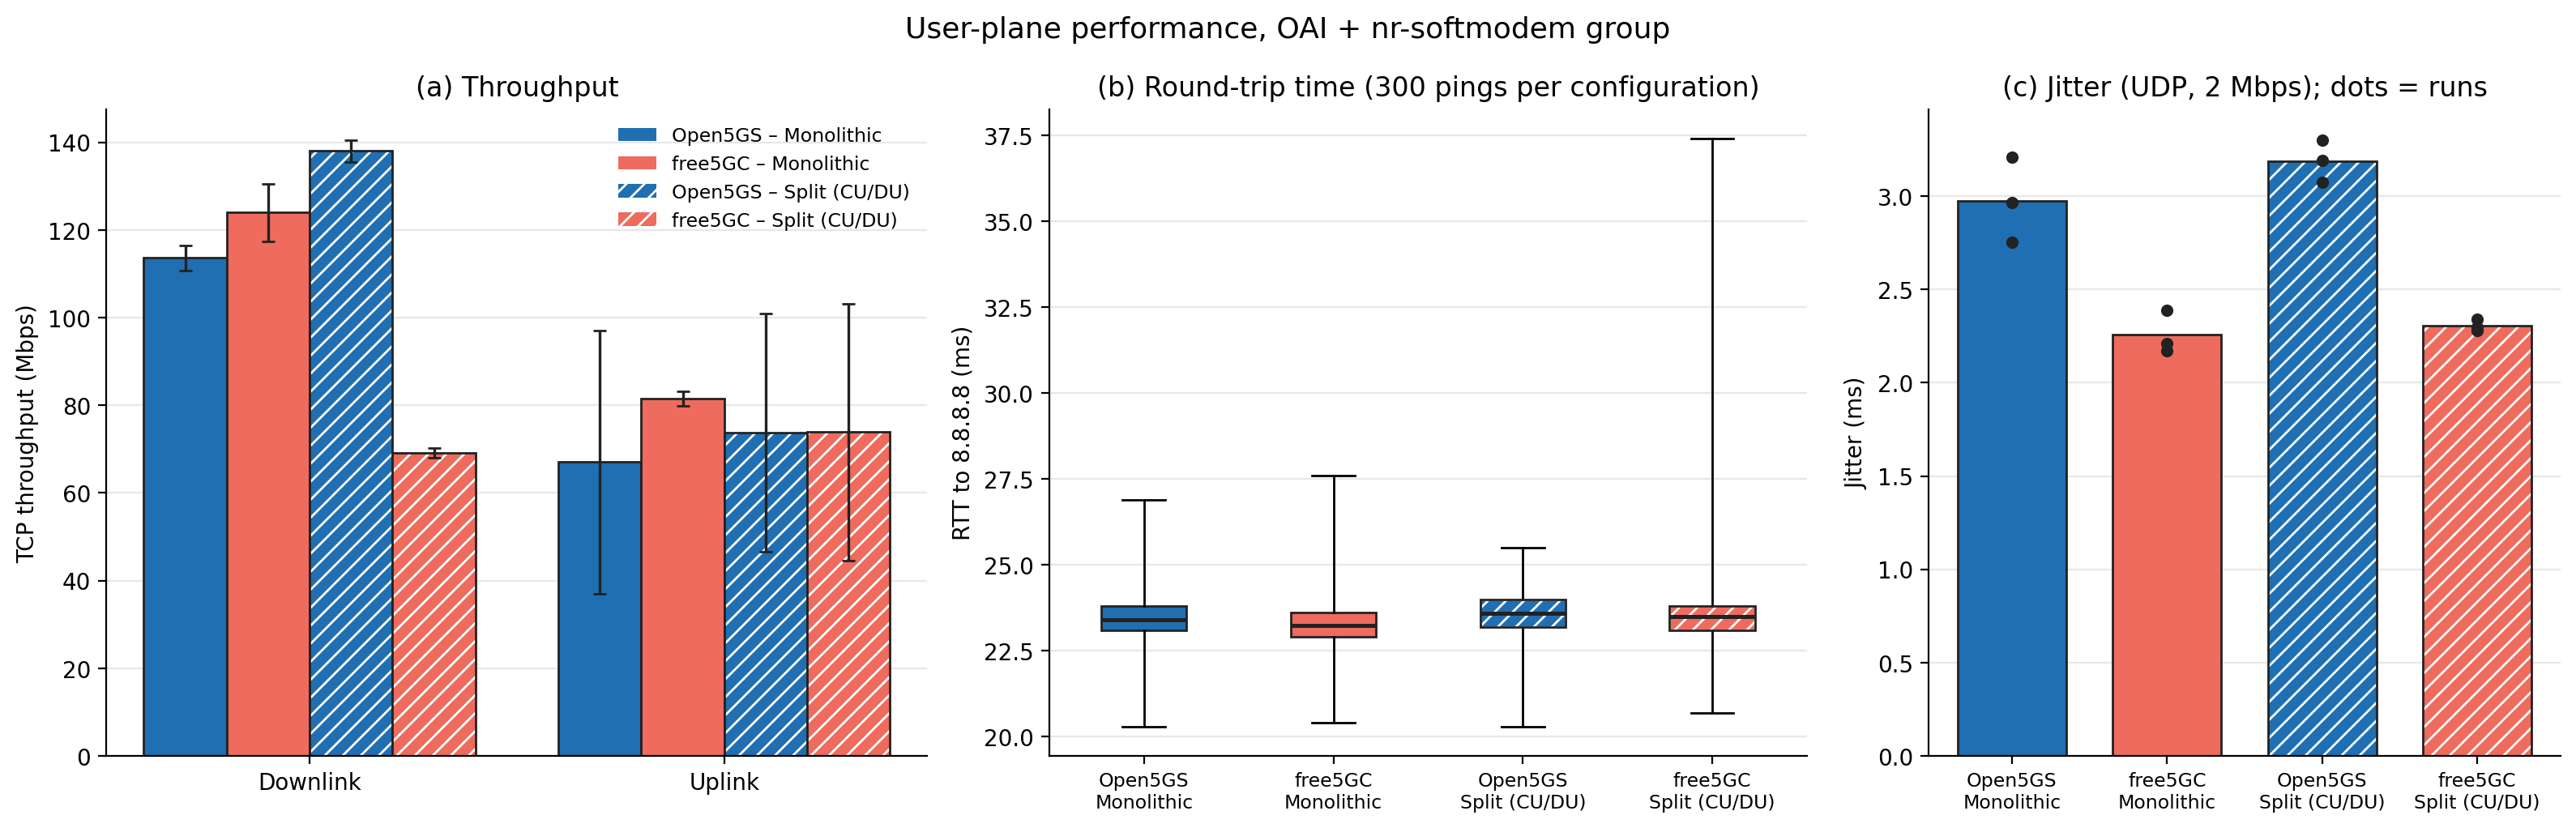

Open5GS – Monolithic: mean 23.3 ms, median 23.4 ms, middle 50% 23.1-23.8 ms, range 20.3-26.9 ms
free5GC – Monolithic: mean 23.2 ms, median 23.2 ms, middle 50% 22.9-23.6 ms, range 20.4-27.6 ms
Open5GS – Split (CU/DU): mean 23.5 ms, median 23.6 ms, middle 50% 23.2-24.0 ms, range 20.3-25.5 ms
free5GC – Split (CU/DU): mean 23.4 ms, median 23.5 ms, middle 50% 23.1-23.8 ms, range 20.7-37.4 ms


In [6]:
plot_user_plane("oai")